# Code Execution with Energy Profiling

In [1]:
# Import modules
import json
import lassi.code_manager
from lassi.get_power import report_gpu_memory
from lassi.format_colors import color

In [3]:
# Code to test and input parameters
source_collection = "HeCBench"
source_app = "dense-embedding"
folder = "source_codes/" + source_collection + "/" + source_app + '/'
code_filename = source_app + "-cuda_main.cu"

# Load config file with source application names and input parameters
with open("source_apps.json", "r") as f:
    source_apps = json.load(f)

exe_input_parameters = source_apps[source_collection][source_app]["app_params"]

# Parameters
power_measure = True
source_language = "CUDA"
target_language = "CUDA"
build_script = False
make_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_89 -O3"
# -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s  # -arch=sm_60 for P100  # -arch=sm_89 for RTX 5000

In [4]:
# Compile code
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_89', '-O3', 'source_codes/HeCBench/dense-embedding/dense-embedding-cuda_main.cu', '-o', 'source_codes/HeCBench/dense-embedding/dense-embedding-cuda_main']

Compilation of code successful!




----- >>> System check BEFORE exe code...

----- GPU Memory Status:
 GPU 0: 435 MiB used, 15940 MiB free, 16376 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 3.04 W, P8



Waiting for the system to settle down for 0 seconds...: 0it [00:00, ?it/s]

executable_file:  source_codes/HeCBench/dense-embedding/dense-embedding-cuda_main
initial_dir:  /home/mdearing/Research/LASSI/LASSI-Verify
directory_path:  source_codes/HeCBench/dense-embedding
executable:  dense-embedding-cuda_main
Working directory: /home/mdearing/Research/LASSI/LASSI-Verify/source_codes/HeCBench/dense-embedding
Execute command: ['./dense-embedding-cuda_main', '100000', '128', '100']



running: executable -  dense-embedding-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Number of rows in the embedding table: 100000
Batch size: 128

Embedding dimension: 768
block size: 128
Average execution time of dense embedding kernel (k1): 0.071960 (us)
Average execution time of dense embedding kernel (k2): 0.023730 (us)
FAIL
block size: 256
Average execution time of dense embedding kernel (k1): 0.023050 (us)
Average execution time of dense embedding kernel (k2): 0.023010 (us)
FAIL
block size: 512
Average execution time of dense embedding kernel (k1): 0.023030 (us)
Average execution time of dense embedding kernel (k2): 0.023030 (us)
FAIL
block size: 1024
Average execution time of dense embedding kernel (k1): 0.023060 (us)
Average execution time of dense embedding kernel (k2): 0.023080 (us)
FAIL

Embedding dimension: 2048
block size: 128
Average execution time of dense embedding kernel (k1): 0.034510 (us)
Average execution time of dense embedding kernel (k2)

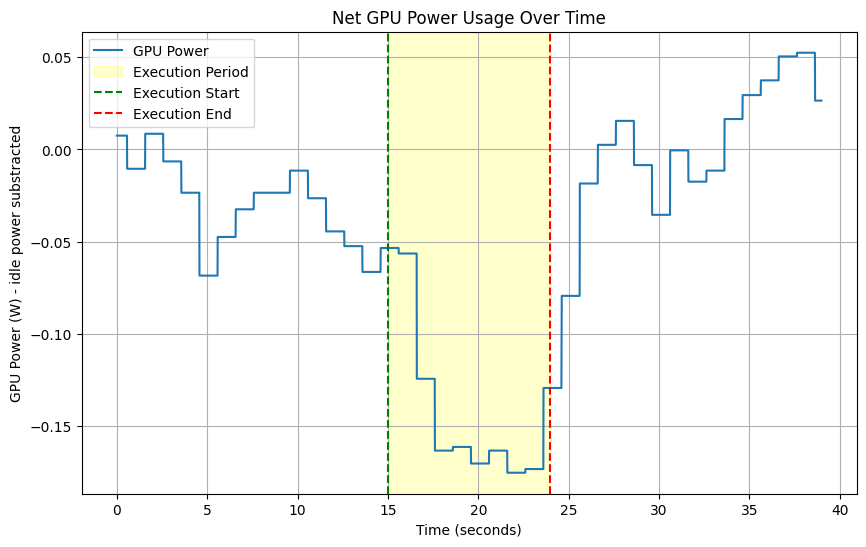

In [6]:
experiment_data_directory = "./temp_amd_test",  # Temporary directory for test
code_version = 1
zero_shot = False
trial_number = 1
directory = ""

# Execute code with Energy Profiling
execute_result, exe_output, total_energy_joules, ave_power, std_power, duration, metrics_results_string = lassi.code_manager.execute_code(
    experiment_data_directory,
    code_version,
    zero_shot,
    trial_number,
    directory,
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    make_script,
    # gpu_vendor="nvidia",  # Explicitly specify AMD
    wait=0
)

## Optional - Measure system idle power
Using same runtime as code execution above.

Measure system idle power...
Duration for idle time measurement: 5.95
GPU power data has been written to idle__gpu_net_power_results.csv


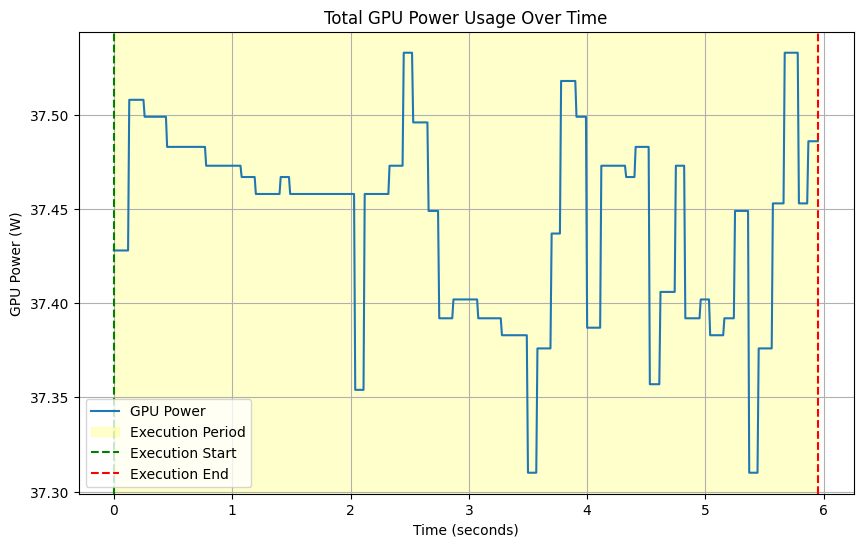

Start time: 0 -- End time: 5.955
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000062 kWh
  0.0620 Wh
  223.17 J
Average GPU power: 37.44 W +/- 0.05 
 with sample standard deviation.
Total Energy During Exe Runtime:   223.17 J
Code execution duration:  5.95 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Idle power measured values for same runtime as all-pairs-distance-cuda_main.cu
Average GPU power: 37.44 W +/- 0.05
Total Energy During Code Runtime: 223.17 J


In [5]:
# OPTIONAL
# Measure system idle power
print("Measure system idle power...")

idle_energy_joules, idle_ave_power, std_idle_ave_power = lassi.get_power.idlepower(duration)

print(color.BOLD + color.BLUE + "\nIdle power measured values for same runtime as " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{idle_ave_power:.2f} W +/- {std_idle_ave_power}" + color.END)
print("Total Energy During Code Runtime: " + color.BOLD + f"{idle_energy_joules:.2f} J" + color.END)